# ME249 Fall 2026 - Project 2 - Extra Task ET1
**Fractional sensitivity of the heat flux of Eq. (1.5) to superheat, gravity, surface tension parameter and pressure**

Uses the best-fit constants of Task 2.3 (file `results/task23.json` written by `P2_Task2.3.ipynb`).

In [1]:
'''>>>>> Extra Task ET1 - fractional sensitivity of the heat flux predicted by Eq. (1.5)
   q" = n1 (Tw-Tsat)^n2 (g + n4 gen gamma)^n3 P^n5
   with the best-fit constants of Task 2.3 (read from results/task23.json written by P2_Task2.3).'''
from __future__ import print_function
import math, json, numpy
%matplotlib inline
import matplotlib.pyplot as plt

gen_en = 9.8
best = json.load(open('results/task23.json'))['best']
n1, n2, n3, n4, n5 = best['n1'], best['n2'], best['n3'], best['n4'], best['n5']
print('Task 2.3 best-fit constants: n1 = %.5e  n2 = %.4f  n3 = %.4f  n4 = %.4f  n5 = %.4f' % (n1, n2, n3, n4, n5))

def qpp(dT, g, gam, P):
    return n1 * dT**n2 * (g + n4 * gen_en * gam)**n3 * P**n5

# typical sets of inputs [(Tw-Tsat)1, g1, gamma1, P1]
STATES = {'S1 (earth gravity)': (40.0, 9.8, 1.79, 5.5),
          'S2 (microgravity)':  (40.0, 0.098, 1.79, 5.5),
          'S3 (2 gen, 9.5 kPa)': (35.0, 19.6, 1.79, 9.5)}
DX_SUPERHEAT = 2.0      # deg C  (step 2 of the statement)
FRAC = 0.05             # 5 % step for g, gamma and P (same relative size as 2 C / 40 C)

et1 = {}
for sname, (dT1, g1, gam1, P1) in STATES.items():
    q1 = qpp(dT1, g1, gam1, P1)                                    # step 1
    out = {'q1': q1}
    for var, x1 in [('dT', dT1), ('g', g1), ('gamma', gam1), ('P', P1)]:
        dx = DX_SUPERHEAT if var == 'dT' else FRAC * x1
        args = dict(dT=dT1, g=g1, gam=gam1, P=P1)
        args['gam' if var == 'gamma' else var] = x1 + dx              # step 2: change only this input
        q2 = qpp(**args)
        S = (q2 - q1) * x1 / (dx * q1)                                 # step 3: fractional change ratio
        out[var] = dict(x1=x1, dx=dx, q2=q2, S=S)
    # analytical logarithmic derivatives (limit dx -> 0), for comparison
    s = g1 + n4 * gen_en * gam1
    out['analytic'] = dict(dT=n2, g=n3 * g1 / s, gamma=n3 * n4 * gen_en * gam1 / s, P=n5)
    et1[sname] = out
    print('\n%s: Tw-Tsat = %.1f C, g = %.3f m/s2, gamma = %.2f, P = %.1f kPa  ->  q"1 = %.2f W/cm2' % (sname, dT1, g1, gam1, P1, q1))
    for var in ['dT', 'g', 'gamma', 'P']:
        o = out[var]
        print('   %-6s x1 = %7.3f  dx = %6.3f  q"2 = %7.2f  dq"/q" / (dx/x) = %7.4f   (analytic %.4f)'
              % (var, o['x1'], o['dx'], o['q2'], o['S'], out['analytic'][var]))


Task 2.3 best-fit constants: n1 = 1.19730e-04  n2 = 3.0216  n3 = 0.4619  n4 = 1.3485  n5 = 0.5435

S1 (earth gravity): Tw-Tsat = 40.0 C, g = 9.800 m/s2, gamma = 1.79, P = 5.5 kPa  ->  q"1 = 106.04 W/cm2
   dT     x1 =  40.000  dx =  2.000  q"2 =  122.89  dq"/q" / (dx/x) =  3.1769   (analytic 3.0216)
   g      x1 =   9.800  dx =  0.490  q"2 =  106.76  dq"/q" / (dx/x) =  0.1348   (analytic 0.1353)
   gamma  x1 =   1.790  dx =  0.090  q"2 =  107.76  dq"/q" / (dx/x) =  0.3235   (analytic 0.3266)
   P      x1 =   5.500  dx =  0.275  q"2 =  108.89  dq"/q" / (dx/x) =  0.5375   (analytic 0.5435)

S2 (microgravity): Tw-Tsat = 40.0 C, g = 0.098 m/s2, gamma = 1.79, P = 5.5 kPa  ->  q"1 = 90.53 W/cm2
   dT     x1 =  40.000  dx =  2.000  q"2 =  104.91  dq"/q" / (dx/x) =  3.1769   (analytic 3.0216)
   g      x1 =   0.098  dx =  0.005  q"2 =   90.53  dq"/q" / (dx/x) =  0.0019   (analytic 0.0019)
   gamma  x1 =   1.790  dx =  0.090  q"2 =   92.58  dq"/q" / (dx/x) =  0.4540   (analytic 0.4600)
   P    

In [2]:
'''(added) common figure style for the report figures + output folders'''
import os, json, logging
logging.getLogger('fontTools').setLevel(logging.ERROR)   # silence font-embedding warnings
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

# categorical colours (fixed order) and single-hue sequential ramp for surfaces
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
MK = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']          # marker shapes = secondary encoding
INK, INK2, GRID = '#0b0b0b', '#52514e', '#dedcd5'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])

mpl.rcParams.update({
    'font.size': 11, 'axes.titlesize': 11, 'axes.labelsize': 11, 'legend.fontsize': 9.5,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.6, 'lines.markersize': 6, 'legend.frameon': False,
    'figure.figsize': [6.4, 4.6], 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'pdf.fonttype': 42})

FIGDIR = '../report/figures/'      # figures used in the LaTeX report
RESDIR = 'results/'                # numerical results (json) used in the report tables
os.makedirs(FIGDIR, exist_ok=True)
os.makedirs(RESDIR, exist_ok=True)

def savefig(name):
    plt.savefig(FIGDIR + name + '.pdf')
    plt.show()

def first_below(hist, thr):
    '''first generation at which a history drops below thr (-1 if never)'''
    for k, v in enumerate(hist):
        if v < thr:
            return k
    return -1

def sci(x, d=2):
    '''LaTeX scientific notation for figure labels, e.g. 1.73 x 10^-3'''
    e = int(math.floor(math.log10(abs(x))))
    return r'%.*f\times10^{%d}' % (d, x / 10**e, e)

def plain_log_ticks(ax, xt=None, yt=None):
    '''plain (non-scientific) tick labels on log axes'''
    from matplotlib.ticker import NullFormatter, NullLocator
    if xt is not None:
        ax.set_xticks(xt); ax.set_xticklabels(['%g' % v for v in xt])
        ax.xaxis.set_minor_locator(NullLocator()); ax.xaxis.set_minor_formatter(NullFormatter())
    if yt is not None:
        ax.set_yticks(yt); ax.set_yticklabels(['%g' % v for v in yt])
        ax.yaxis.set_minor_locator(NullLocator()); ax.yaxis.set_minor_formatter(NullFormatter())

def best_so_far(h):
    return numpy.minimum.accumulate(numpy.array(h))


S1 (earth gravity):
   (i)   single input : dT < 0.047, g < 1.113, gamma < 0.464, P < 0.279   -> superheat within +/- 1.89 C
   (ii)  worst case   : eps < 0.0359  (superheat +/- 1.44 C, g +/- 0.352 m/s2, gamma +/- 0.064, P +/- 0.198 kPa); nonlinear check dq"/q" = 0.1528
   (iii) RSS          : eps < 0.0463  (superheat +/- 1.85 C)
S2 (microgravity):
   (i)   single input : dT < 0.047, g < 78.717, gamma < 0.330, P < 0.279   -> superheat within +/- 1.89 C
   (ii)  worst case   : eps < 0.0360  (superheat +/- 1.44 C, g +/- 0.004 m/s2, gamma +/- 0.064, P +/- 0.198 kPa); nonlinear check dq"/q" = 0.1529
   (iii) RSS          : eps < 0.0461  (superheat +/- 1.84 C)
S3 (2 gen, 9.5 kPa):
   (i)   single input : dT < 0.047, g < 0.721, gamma < 0.598, P < 0.279   -> superheat within +/- 1.64 C
   (ii)  worst case   : eps < 0.0358  (superheat +/- 1.25 C, g +/- 0.701 m/s2, gamma +/- 0.064, P +/- 0.340 kPa); nonlinear check dq"/q" = 0.1519
   (iii) RSS          : eps < 0.0460  (superheat +/- 1.61 C)


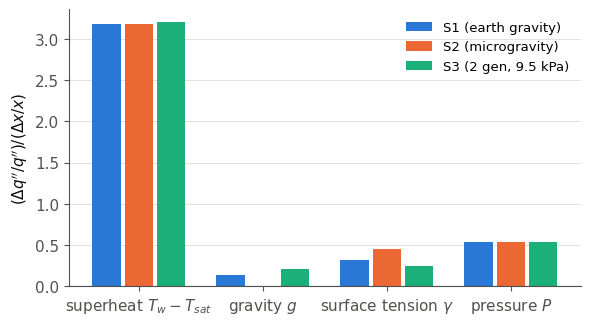

In [3]:
'''ET1 - limiting fractional inaccuracy of the inputs for |dq"/q"| < 0.15
   To first order  dq"/q" = S_dT dT/dT + S_g dg/g + S_gamma dgamma/gamma + S_P dP/P, so:
   (i)   one input inaccurate at a time   : eps_x < 0.15 / |S_x|
   (ii)  all inputs with the same eps, errors adding in the worst direction : eps < 0.15 / sum|S_x|
   (iii) same eps, independent random errors (root-sum-square)            : eps < 0.15 / sqrt(sum S_x^2)'''
QTOL = 0.15
VARS = ['dT', 'g', 'gamma', 'P']
lim = {}
for sname, out in et1.items():
    S = numpy.array([abs(out[v]['S']) for v in VARS])
    single = QTOL / S
    worst = QTOL / S.sum()
    rss = QTOL / math.sqrt((S**2).sum())
    lim[sname] = dict(single=dict(zip(VARS, single.tolist())), worst=worst, rss=rss)
    # nonlinear check: all inputs off by the worst-case eps in the direction that increases q"
    dT1, g1, gam1, P1 = [out[v]['x1'] for v in VARS]
    sgn = numpy.sign([out[v]['S'] for v in VARS])
    qw = qpp(dT1 * (1 + sgn[0] * worst), g1 * (1 + sgn[1] * worst), gam1 * (1 + sgn[2] * worst), P1 * (1 + sgn[3] * worst))
    lim[sname]['check_worst'] = qw / out['q1'] - 1
    print('%s:' % sname)
    print('   (i)   single input : ' + ', '.join('%s < %.3f' % (v, e) for v, e in zip(VARS, single)) +
          '   -> superheat within +/- %.2f C' % (single[0] * dT1))
    print('   (ii)  worst case   : eps < %.4f  (superheat +/- %.2f C, g +/- %.3f m/s2, gamma +/- %.3f, P +/- %.3f kPa);'
          ' nonlinear check dq"/q" = %.4f' % (worst, worst * dT1, worst * g1, worst * gam1, worst * P1, lim[sname]['check_worst']))
    print('   (iii) RSS          : eps < %.4f  (superheat +/- %.2f C)' % (rss, rss * dT1))

fig, ax = plt.subplots(figsize=(6.6, 3.6))
w = 0.26
for c, (sname, out) in enumerate(et1.items()):
    ax.bar(numpy.arange(4) + (c - 1) * w, [out[v]['S'] for v in VARS], width=w - 0.03, color=C[c], label=sname)
ax.set_xticks(range(4))
ax.set_xticklabels([r'superheat $T_w-T_{sat}$', r'gravity $g$', r'surface tension $\gamma$', r'pressure $P$'])
ax.set_ylabel(r'$(\Delta q^{\prime\prime}/q^{\prime\prime})/(\Delta x/x)$')
ax.axhline(0, color='#52514e', lw=0.8)
ax.legend(loc='upper right')
ax.grid(axis='x', visible=False)
savefig('et1_sensitivity')
json.dump(dict(constants=best, states=STATES, sens=et1, limits=lim), open(RESDIR + 'et1.json', 'w'), indent=1)
